
# Phase 5: Confidence Evaluation

## Objective

The goal of this phase is to make the model's predictions more reliable and interpretable.

Instead of simply predicting whether a code submission was written by a human or AI, we also want to estimate how confident the model is in its prediction.

This phase has two main components:

1. **Probability Calibration:** Adjusting the model's predicted probabilities so that they better reflect actual outcomes.
2. **Confidence Bands:** Grouping predictions into low, medium, high, and inconclusive confidence levels.

We use validation data to fit calibration parameters and determine confidence thresholds. The test set is kept separate for final evaluation.


In [1]:

import pandas as pd
import json
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
ROOT = Path("..")

# Load calibration evaluation
calibration = pd.read_csv(
    ROOT / "results/phase45/calibration_summary.csv"
)

# Load confidence-band results
bands_val = pd.read_csv(
    ROOT / "results/phase45/confidence_bands_val.csv"
)

bands_test = pd.read_csv(
    ROOT / "results/phase45/confidence_bands_test.csv"
)

# Load saved calibration parameters
with open(ROOT / "models/calibration.json") as f:
    calibration_params = json.load(f)

# Load saved confidence thresholds
with open(ROOT / "models/confidence_cuts.json") as f:
    confidence_cuts = json.load(f)

print("Calibration results:")
display(calibration)

print("\nValidation confidence bands:")
display(bands_val)

print("\nTest confidence bands:")
display(bands_test)

print("\nCalibration parameters:", calibration_params)
print("\nConfidence thresholds:", confidence_cuts)


Calibration results:


,set,n,ECE raw,ECE calibrated,Brier raw,Brier calibrated,AUC raw,AUC calibrated
0,validation (used to fit),1005,0.1153,0.0347,0.1653,0.1494,0.8235,0.8235
1,test,1009,0.1077,0.0478,0.1690,0.1545,0.8020,0.8020



Validation confidence bands:


,band,files,share,accuracy,ai_verdicts,ai_precision
0,low,285,0.283582,0.687719,146,0.650685
1,medium,284,0.282587,0.862676,46,0.913043
2,high,285,0.283582,0.922807,48,1.000000
3,inconclusive,151,0.150249,0.596026,91,0.472527
4,answered (not inconclusive),854,0.849751,0.824356,240,0.770833
5,all files,1005,1.000000,0.790050,331,0.688822



Test confidence bands:


,band,files,share,accuracy,ai_verdicts,ai_precision
0,low,286,0.283449,0.727273,130,0.653846
1,medium,315,0.312190,0.857143,46,0.978261
2,high,259,0.256690,0.895753,41,1.000000
3,inconclusive,149,0.147671,0.550336,74,0.472973
4,answered (not inconclusive),860,0.852329,0.825581,217,0.788018
5,all files,1009,1.000000,0.784936,291,0.707904



Calibration parameters: {'coef': 1.0253460240149994, 'intercept': -0.6368389000262481}

Confidence thresholds: {'t_cal': 0.44973792443136235, 'delta': 0.09766985322997752, 'low_max': 0.7731801077794564, 'high_min': 0.8862595969466068, 'zone_coverage': 0.15}



## 2. Confidence Band Evaluation

After calibration, predictions are assigned to four confidence categories:

- **Low:** The model has relatively low confidence.
- **Medium:** The model has moderate confidence.
- **High:** The model has strong confidence.
- **Inconclusive:** The prediction falls close to the decision threshold, so the system avoids making a definitive classification.

We evaluate these categories using the test set to determine whether higher confidence corresponds to better prediction accuracy.


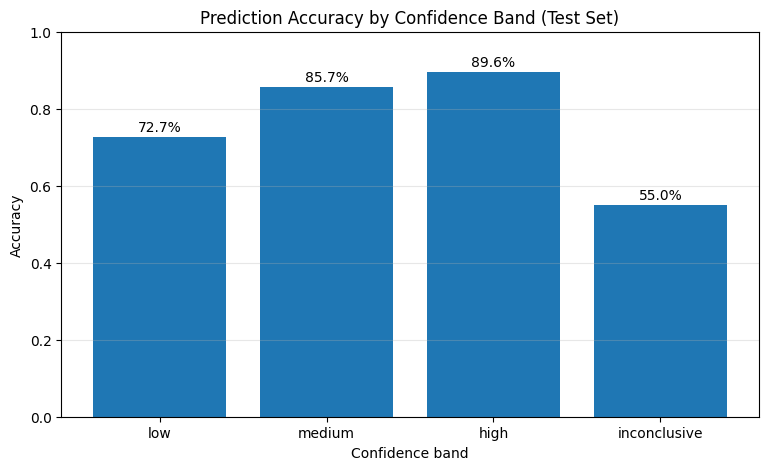

In [2]:

# Remove summary rows because we only want individual confidence bands
test_plot = bands_test[
    bands_test["band"].isin(["low", "medium", "high", "inconclusive"])
].copy()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    test_plot["band"],
    test_plot["accuracy"]
)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Confidence band")
plt.title("Prediction Accuracy by Confidence Band (Test Set)")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, test_plot["accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.015,
        f"{value:.1%}",
        ha="center"
    )

plt.show()



## 3. Abstention Analysis

The system does not have to classify every submission.

When the calibrated probability falls within the inconclusive zone, the system abstains from making a definitive prediction.

This creates a trade-off:

- Lower coverage means the system answers fewer submissions.
- Higher coverage means the system answers more submissions, but may include less reliable predictions.

We evaluate whether abstaining from inconclusive predictions improves the accuracy of the remaining predictions.


In [3]:

# Compare overall performance with and without abstention

test_all = bands_test[
    bands_test["band"] == "all files"
].iloc[0]

test_answered = bands_test[
    bands_test["band"] == "answered (not inconclusive)"
].iloc[0]

coverage = test_answered["files"] / test_all["files"]

print(f"Total submissions: {int(test_all['files'])}")
print(f"Submissions answered: {int(test_answered['files'])}")
print(f"Coverage: {coverage:.1%}")
print(f"Accuracy on all submissions: {test_all['accuracy']:.1%}")
print(f"Accuracy on answered submissions: {test_answered['accuracy']:.1%}")
print(f"Abstention rate: {1 - coverage:.1%}")


Total submissions: 1009
Submissions answered: 860
Coverage: 85.2%
Accuracy on all submissions: 78.5%
Accuracy on answered submissions: 82.6%
Abstention rate: 14.8%



## 4. Validation vs Test Performance

We compare validation and test results to check whether the confidence strategy generalizes to unseen data.

The validation set was used to fit the calibration parameters and determine confidence thresholds. The test set was kept separate to evaluate the final performance of the approach.


In [ ]:

# Compare accuracy and coverage across validation and test sets

def get_summary(df):
    all_files = df[df["band"] == "all files"].iloc[0]
    answered = df[
        df["band"] == "answered (not inconclusive)"
    ].iloc[0]

    return {
        "Set": "Validation" if df is bands_val else "Test",
        "Total files": int(all_files["files"]),
        "Coverage": answered["share"],
        "Abstention rate": 1 - answered["share"],
        "Accuracy (all)": all_files["accuracy"],
        "Accuracy (answered)": answered["accuracy"]
    }

comparison = pd.DataFrame([
    get_summary(bands_val),
    get_summary(bands_test)
])

display(
    comparison.style.format({
        "Coverage": "{:.1%}",
        "Abstention rate": "{:.1%}",
        "Accuracy (all)": "{:.1%}",
        "Accuracy (answered)": "{:.1%}"
    })
)



## 5. Final Conclusions

The confidence evaluation produced the following findings:

1. **Calibration improved probability reliability.** On the test set, ECE decreased from 0.1077 to 0.0478, while the Brier score decreased from 0.1690 to 0.1545.

2. **Discrimination remained unchanged.** AUC stayed at 0.8020 because probability calibration did not change the model's ranking of submissions.

3. **Confidence bands showed meaningful differences.** Test accuracy increased from 72.7% in the low-confidence band to 89.6% in the high-confidence band.

4. **Abstention improved answered-prediction accuracy.** By abstaining on 14.8% of test submissions, accuracy on the remaining predictions increased from 78.5% to 82.6%.

5. **The results were consistent across validation and test data.** Coverage and answered-prediction accuracy were similar across both sets.

### Limitations

- Calibration improves probability reliability but does not eliminate classification errors.
- The inconclusive group still contains useful predictions, but their reliability is relatively low.
- High-confidence AI precision was 100% on the test set, but this represents only 41 AI predictions. It should not be interpreted as a guarantee of correctness.
- The model can still confidently misclassify some AI-generated submissions.

### Overall Conclusion

The confidence layer makes the detection system more informative by communicating prediction reliability and allowing it to abstain when uncertain. It improves the quality of definitive predictions, although it does not eliminate the underlying model's errors.
